In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error


In [33]:
data = pd.read_csv('/content/Assignment_1_Dataset.csv')

In [34]:
data.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91
1,4,82,No,4,2,65
2,8,51,Yes,7,2,45
3,5,52,Yes,5,2,36
4,7,75,No,8,5,66


In [35]:
data.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [36]:
data.tail()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
9995,1,49,Yes,4,2,23
9996,7,64,Yes,8,5,58
9997,6,83,Yes,8,5,74
9998,9,97,Yes,7,0,95
9999,7,74,No,8,1,64


In [37]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype 
---  ------                            --------------  ----- 
 0   Hours Studied                     10000 non-null  int64 
 1   Previous Scores                   10000 non-null  int64 
 2   Extracurricular Activities        10000 non-null  object
 3   Sleep Hours                       10000 non-null  int64 
 4   Sample Question Papers Practiced  10000 non-null  int64 
 5   Performance Index                 10000 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 468.9+ KB


In [38]:
#checking missing values
data.isnull().sum()

,0
Hours Studied,0
Previous Scores,0
Extracurricular Activities,0
Sleep Hours,0
Sample Question Papers Practiced,0
Performance Index,0


In [39]:
#canja sunaye su koma lambobi (binary)
Data_encoded = pd.get_dummies(data, drop_first=True)

In [40]:
Data_encoded

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index,Extracurricular Activities_Yes
0,7,99,9,1,91,True
1,4,82,4,2,65,False
2,8,51,7,2,45,True
3,5,52,5,2,36,True
4,7,75,8,5,66,False
...,...,...,...,...,...,...
9995,1,49,4,2,23,True
9996,7,64,8,5,58,True
9997,6,83,8,5,74,True
9998,9,97,7,0,95,True


In [41]:
#splitting x and y
X = Data_encoded.drop(columns = ['Performance Index'])
Y = Data_encoded[['Performance Index']]

In [42]:
X

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Extracurricular Activities_Yes
0,7,99,9,1,True
1,4,82,4,2,False
2,8,51,7,2,True
3,5,52,5,2,True
4,7,75,8,5,False
...,...,...,...,...,...
9995,1,49,4,2,True
9996,7,64,8,5,True
9997,6,83,8,5,True
9998,9,97,7,0,True


In [43]:
#splitting training/test set 80% and 20%
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [44]:
#feature scaling
Scaler_x = StandardScaler()
X_train_scaled = Scaler_x.fit_transform(X_train)   # fit on TRAIN
X_test_scaled  = Scaler_x.transform(X_test)

LR = LinearRegression()
LR.fit(X_train_scaled, Y_train)                    # train on scaled data
predicted = LR.predict(X_test_scaled)

In [45]:
#train the model
LR=LinearRegression()
LR.fit(X_train,Y_train)

predicted=LR.predict(X_test)

In [46]:
#evaluating model performance
r2 = r2_score(Y_test, predicted)
print(f"r2: {r2}")

mse = mean_squared_error(Y_test, predicted)
print(f"Mean Squared Error: {mse}")

mae = mean_absolute_error(Y_test, predicted)
print(f"Mean Absolute Error: {mae}")


r2: 0.9889832909573145
Mean Squared Error: 4.082628398521851
Mean Absolute Error: 1.611121346312304


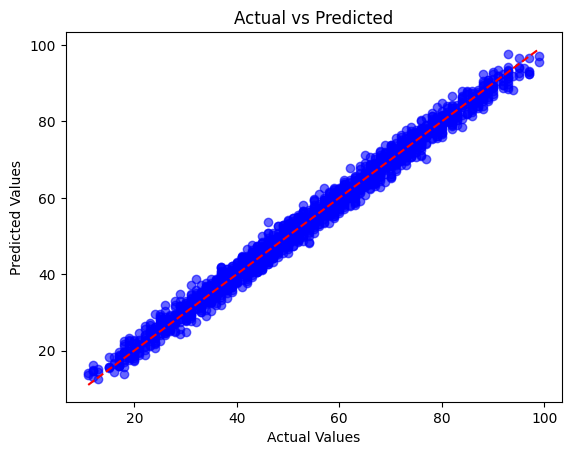

In [47]:
# plot the actual vs Predicted by model
import matplotlib.pyplot as plt
import numpy as np

# Ensure both are numpy arrays
y_true = np.array(Y_test)
y_pred = np.array(predicted)

plt.scatter(y_true, y_pred, color='blue', alpha=0.6)

# Get the limits for the line
min_val = min(y_true.min(), y_pred.min())
max_val = max(y_true.max(), y_pred.max())

# Plot 45-degree reference line
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted')
plt.show()


In [48]:
new_data = pd.DataFrame({
    'Hours Studied': [2],
    'Previous Scores': [54],
    'Extracurricular Activities': ['Yes'],
    'Sleep Hours': [4],
    'Sample Question Papers Practiced': [5]
})

new_data_encoded = pd.get_dummies(new_data, drop_first=True)
new_data_encoded = new_data_encoded.reindex(columns=X.columns, fill_value=0)

new_prediction = LR.predict(new_data_encoded)

print(new_data)
print(f"\nPredicted Performance Index: {new_prediction[0][0]:.2f}")

   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              2               54                        Yes            4   

   Sample Question Papers Practiced  
0                                 5  

Predicted Performance Index: 29.57
